In [2]:
import seaborn as sea
import scipy.stats as stats
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

file_path = "../overtime.csv"
df = pd.read_csv(file_path)

df

,Program,Powercap,Timestamp_ms,IntelCPU.Temperature_C,IntelCPU.Package_J,System.RunningProcesses_processes,Time.WallClock_ms
0,fibonacci-40,-1,10.000000,38.75,0.115540,4,10.440635
1,fibonacci-40,-1,20.000000,38.75,0.144592,3,20.588514
2,fibonacci-40,-1,30.000000,38.75,0.147766,3,30.630615
3,fibonacci-40,-1,40.000000,38.75,0.156860,2,40.689678
4,fibonacci-40,-1,50.000000,38.75,0.195679,3,50.814555
...,...,...,...,...,...,...,...
4512,fibonacci-40,5,28650.000000,40.25,0.054688,2,28651.014900
4513,fibonacci-40,5,28660.000000,40.25,0.049500,2,28661.127900
4514,fibonacci-40,5,28670.000000,40.25,0.048828,2,28671.240200
4515,fibonacci-40,5,28680.000000,40.25,0.050293,3,28681.357000


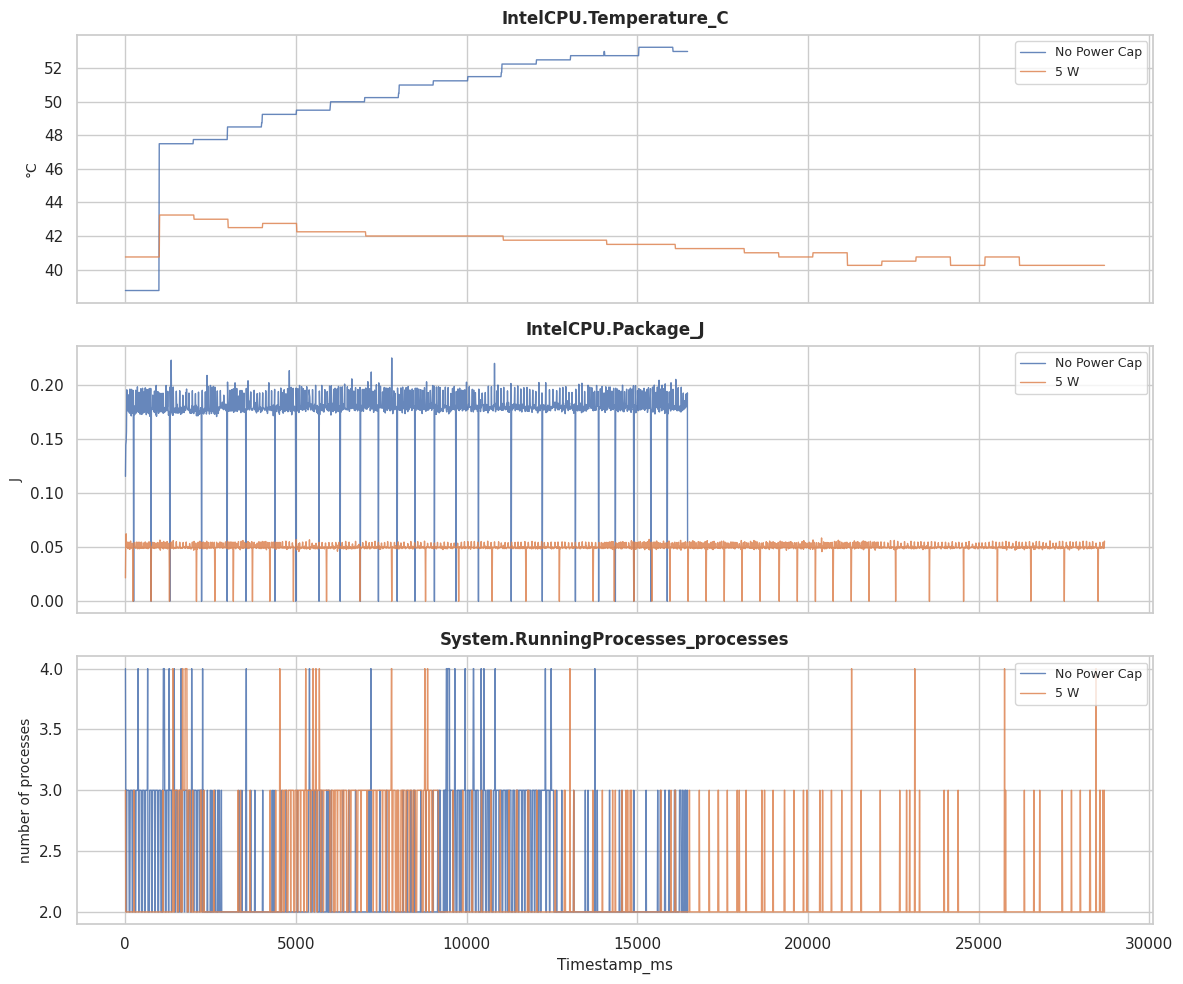

In [3]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns


def plot_overtime_metrics(df: pd.DataFrame, save_path: str = None):
    # Remove the Time.WallClock_ms column
    df_plot = df.drop(columns=["Time.WallClock_ms"], errors="ignore").copy()

    # Ensure numeric types and drop invalid rows if any
    metrics = [
        ("IntelCPU.Temperature_C", "°C"),
        ("IntelCPU.Package_J", "J"),
        ("System.RunningProcesses_processes", "number of processes"),
    ]
    for col, _ in metrics:
        df_plot[col] = pd.to_numeric(df_plot[col], errors="coerce")
    df_plot["Timestamp_ms"] = pd.to_numeric(
        df_plot["Timestamp_ms"], errors="coerce"
    )
    df_plot = df_plot.dropna(subset=["Timestamp_ms"] + [m[0] for m in metrics])

    # Create readable labels for Powercap
    df_plot["Powercap_Label"] = df_plot["Powercap"].apply(
        lambda x: "No Power Cap" if x == -1 else f"{x} W"
    )

    sns.set_theme(style="whitegrid")
    fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
    palette = ["#4C72B0", "#DD8452"]

    for ax, (col, unit) in zip(axes, metrics):
        sns.lineplot(
            data=df_plot,
            x="Timestamp_ms",
            y=col,
            hue="Powercap_Label",
            palette=palette,
            linewidth=1.0,
            alpha=0.85,
            ax=ax,
        )
        ax.set_title(col, fontsize=12, fontweight="bold", pad=8)
        ax.set_ylabel(unit, fontsize=10)
        ax.legend(
            title="", loc="upper right", fontsize=9, title_fontsize=10
        )

    axes[-1].set_xlabel("Timestamp_ms", fontsize=11)

    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")

    plt.show()


# Example usage with your df:
plot_overtime_metrics(df, save_path="over-time.pdf")